In [267]:
import pandas as pd
import seaborn as sns
import numpy as np

In [235]:
df = pd.read_csv('insurance.csv')

In [236]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [237]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [238]:
df.describe(include='all')

,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


In [239]:
df['smoker'].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [240]:
df['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [241]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

#### Concluion
* there are two columns that we will apply map and on region be apply one hot encoding

In [242]:
df['smoker'] = df['smoker'].map({'yes':0,'no':1})

In [243]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,0,southwest,16884.92400
1,18,male,33.770,1,1,southeast,1725.55230
2,28,male,33.000,3,1,southeast,4449.46200
3,33,male,22.705,0,1,northwest,21984.47061
4,32,male,28.880,0,1,northwest,3866.85520


In [244]:
df['sex'] = df['sex'].map({'female':0,'male':1})

In [245]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,0,southwest,16884.92400
1,18,1,33.770,1,1,southeast,1725.55230
2,28,1,33.000,3,1,southeast,4449.46200
3,33,1,22.705,0,1,northwest,21984.47061
4,32,1,28.880,0,1,northwest,3866.85520


In [246]:
df_encoded = pd.get_dummies(df,columns=['region'],drop_first=True,dtype=int)

In [247]:
df_encoded.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,0,16884.92400,0,0,1
1,18,1,33.770,1,1,1725.55230,0,1,0
2,28,1,33.000,3,1,4449.46200,0,1,0
3,33,1,22.705,0,1,21984.47061,1,0,0
4,32,1,28.880,0,1,3866.85520,1,0,0


<Axes: xlabel='bmi', ylabel='charges'>

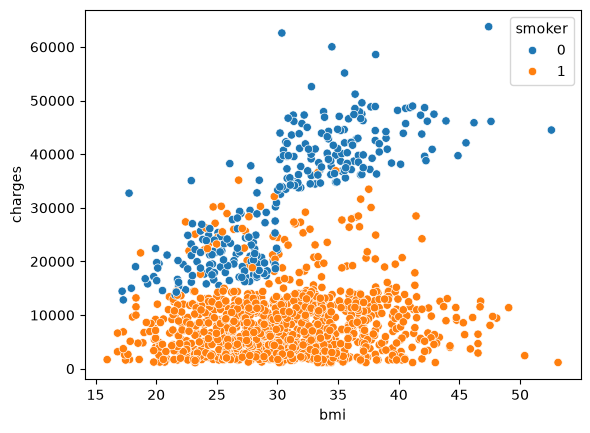

In [248]:
sns.scatterplot(data = df_encoded, x = 'bmi',y = 'charges',hue='smoker')

In [249]:
X = df_encoded.drop('charges',axis=1)
y = df_encoded['charges']

In [250]:
X.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,0,0,0,1
1,18,1,33.770,1,1,0,1,0
2,28,1,33.000,3,1,0,1,0
3,33,1,22.705,0,1,1,0,0
4,32,1,28.880,0,1,1,0,0


In [251]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [252]:
from sklearn.model_selection import train_test_split

In [253]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [254]:
X_train.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
560,46,0,19.95,2,1,1,0,0
1285,47,0,24.32,0,1,0,0,0
1142,52,0,24.86,0,1,0,1,0
969,39,0,34.32,5,1,0,1,0
486,54,0,21.47,3,1,1,0,0


In [255]:
X_test.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
764,45,0,25.175,2,1,0,0,0
887,36,0,30.020,0,1,1,0,0
890,64,0,26.885,0,0,1,0,0
1293,46,1,25.745,3,1,1,0,0
259,19,1,31.920,0,0,1,0,0


In [256]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [257]:
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 256.98, -18.59, 337.09,...,-370.68,-657.86,-809.8 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['age','sex','bmi',...,'region_northwest','region_southeast', 'region_southwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.172e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [258]:
y_pred = model.predict(X_test)

In [261]:
from sklearn.metrics import mean_squared_error,r2_score

In [264]:
mse = mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

In [265]:
print(mse)
print(r2)

33596915.85136144
0.7835929767120724


In [268]:
rmse = np.sqrt(mse)
print(f"Average Error Amount: {rmse}")

Average Error Amount: 5796.284659276271
